# Pareto fronts of pose priors: sample quality against the cost of sampling (proof of concept)

The models of `posedflow_vs_rsgm.ipynb` (PoseD-Flow, DPoser, RSGM on the data of PoseD-Flow) and the HuProSO3 flow, placed
as the MLIP papers place their potentials (e.g. Fig. 1 of the GRACE paper): one panel per metric, the quality on x
(the better side on the left), the time per pose on y (log scale), and the Pareto-optimal models joined by a line.

- **Quality.** Read from the cache of `posedflow_vs_rsgm.ipynb` (`~/data/experiments/posedflow_comparison/cache`), not
  computed again:
  - **Wasserstein** (our harness): optimal transport between 2,000 generated and 2,000 test poses, degrees per joint;
  - **FID** (protocol of PoseD-Flow): Fréchet distance of the 22 SMPL joint positions against their statistics
    `gt_mean_var_v2.npz`, 20 sets of 500 samples;
  - **APD** (protocol of PoseD-Flow): mean pairwise joint distance, cm. Their table reads it as "higher is better";
    it is a diversity, so the value of real poses is drawn as a reference line.

  A model missing from that cache (the HuProSO3 flow) is evaluated here with the same settings and written to the same
  cache, so `posedflow_vs_rsgm.ipynb` reuses it.
- **Cost.** Measured here: the wall-clock time of `model.sample(n)` (noise → valid rotations, all sampler steps),
  median of `REPEATS` runs after a warm-up, with the device synchronized. Two regimes, as ASE / LAMMPS in GRACE:
  - **throughput**: n = `BATCH` (filled markers; the Pareto front is drawn for these);
  - **latency**: n = 1 (open markers).

  The times are of this machine and device only; they are cached next to the metrics, one file per chip and device
  (`runtime_<chip>_<device>.json`), with the chip, device, platform and torch version in the settings.
- **† = trained on our AMASS** (SMPL-X G), evaluated on the data of PoseD-Flow: a data shift that the others do not have.
  The HuProSO3 flow is the only such model here. It is drawn as a reference for the speed of a one-pass sampler (a
  diamond), and is left out of the Pareto fronts.

In [1]:
import json
import platform
import re
import subprocess
import sys
import time
from functools import lru_cache
from pathlib import Path

# the code of the checkout this notebook is in (e.g. a worktree), before an editable install of another one
SRC = next(str(p / "src") for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "hp").is_dir())
if SRC not in sys.path:
    sys.path.insert(0, SRC)

import matplotlib.pyplot as plt
import numpy as np
import torch

from hp.evaluation.data import load_reference
from hp.evaluation.evaluate import EvalConfig, evaluate
from hp.evaluation.posedflow_protocol import SmplSkeleton, apd, confidence, fid, nearest_neighbour_distance
from hp.models.io import MANIFEST, load_model
from hp.models.posedflow import PoseDFlowPretrained

assert load_model.__module__ == "hp.models.io" and sys.modules["hp.models.io"].__file__.startswith(SRC), \
    f"hp comes from {sys.modules['hp.models.io'].__file__}: restart the kernel"

# ---- parameters ----------------------------------------------------------------------
# The data and the evaluation settings of posedflow_vs_rsgm.ipynb: change them together, or the cache does not match.
ROTATIONS = "~/data/AMASS_rotations_posedflow_c10"
CHECKPOINT = "~/data/posedflow_ckpt/checkpoints/epoch-009_step-0_loss-0.0000.ckpt"
SKELETON = "~/data/body_models/smpl/smpl_neutral_skeleton.npz"
GT_STATS = "~/Documents/PoseDFlow/examples/gt_mean_var_v2.npz"
HARNESS = EvalConfig()  # 20k samples, 2000 queries, 3 repeats
N_CONTRAST = 100_000
SETS, SET_SIZE = 20, 500
CACHE = Path("~/data/experiments/posedflow_comparison/cache").expanduser()

# The models: the specs (and names, which key the cache) of posedflow_vs_rsgm.ipynb, plus the HuProSO3 flow.
# "short": the label in the plots. Specs as there: posedflow=dict(...) for their checkpoint, run=<folder or list>.
MODELS = {
    "PoseD-Flow: their checkpoint, midpoint 100 (paper)": dict(short="PoseD-Flow, mid 100",
        posedflow=dict(weights="ema", method="midpoint", sample_steps=100)),
    # "PoseD-Flow: their checkpoint, Euler 1000 raw (their script)": dict(short="PoseD-Flow, Euler 1000",
    #     posedflow=dict(weights="raw", method="euler", sample_steps=1000)),
    # "PoseD-Flow retrained: our AMASS, midpoint 100": dict(short="PoseD-Flow†, mid 100", run="~/data/experiments/posedflow_amass_s10"),
    "DPoser: their full, 1000 steps": dict(short="DPoser full, 1000", run="~/data/experiments/full/dposer_posedflow_s10"),
    "DPoser: their full, 100 steps": dict(short="DPoser full, 100", run="~/data/experiments/full/dposer_posedflow_s10", sample_steps=100),
    "DPoser: their c10 (RSGM budget), 1000 steps": dict(short="DPoser c10, 1000", run="~/data/experiments/dposer_posedflow_rsgm_budget_s10"),
    "DPoser: their c10 (RSGM budget), 100 steps": dict(short="DPoser c10, 100", run="~/data/experiments/dposer_posedflow_rsgm_budget_s10", sample_steps=100),
    # "RSGM 1024x3 t23: our AMASS": dict(short="RSGM 1024x3†", run="~/data/experiments/rsgm_tuned_t23"),
    "RSGM 512x4: their full": dict(short="RSGM 512x4 full", run="~/data/experiments/full/rsgm_posedflow_small_s10"),
    "RSGM 512x4: their c10 (3 seeds)": dict(short="RSGM 512x4", run=[f"~/data/experiments/rsgm_posedflow_small_s{seed}" for seed in (10, 11, 12)]),
    "RSGM 1536x6: their c10": dict(short="RSGM 1536x6", run="~/data/experiments/rsgm_posedflow_s10"),
    "RSGM 4096x7: their c10, final (30k)": dict(short="RSGM 4096x7", run="~/data/experiments/rsgm_posedflow_large_s10"),
    # "RSGM 4096x7: their c10, best (8k)": dict(short="RSGM 4096x7 @8k", run="~/data/experiments/rsgm_posedflow_large_s10/run_0001/checkpoint_008000"),
    "RSGM 512x4: their c10, 300 steps": dict(short="RSGM 512x4, 300", run="~/data/experiments/rsgm_posedflow_small_s10", sample_steps=300),
    "RSGM 512x4: their c10, 1000 steps": dict(short="RSGM 512x4, 1000", run="~/data/experiments/rsgm_posedflow_small_s10", sample_steps=1000),
    # "RSGM 512x4: their c10, eps 2e-3": dict(short="RSGM 512x4, eps 2e-3", run="~/data/experiments/rsgm_posedflow_small_s10", eps=2e-3),
    # "RSGM 512x4: their c10, eps 1e-2": dict(short="RSGM 512x4, eps 1e-2", run="~/data/experiments/rsgm_posedflow_small_s10", eps=1e-2),
    # "RSGM 512x4: their c10, raw weights": dict(short="RSGM 512x4, raw", run="~/data/experiments/rsgm_posedflow_small_s10", weights="weights"),
    # ---- new here: the HuProSO3 flow of the paper's settings, trained on our AMASS (all frames, seed 11), final weights
    "HuProSO3 flow: our AMASS": dict(short="HuProSO3 flow†", run="~/data/experiments/huproso3_full_seed11", weights="weights"),
}
# Drawn, but left out of the Pareto fronts: trained on other data than the models it would be compared with
FRONT_EXCLUDE = {"HuProSO3 flow: our AMASS"}

# the families, in a fixed order of colours; RSGM (ours) in red, as GRACE in its figure
FAMILIES = {"RSGM": "#e34948", "PoseD-Flow": "#2a78d6", "DPoser": "#eb6834", "HuProSO3": "#1baf7a"}

DEVICE = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
BATCH = 4096  # throughput
REPEATS = 3
RECOMPUTE = set()  # names of models (or "<name> / <run>") to evaluate again (Wasserstein, FID, APD); True: all
RECOMPUTE_RUNTIME = set()  # names of models (or "<name> / <run>") to time again; True: all
# --------------------------------------------------------------------------------------
print(f"device {DEVICE}, {platform.platform()}, torch {torch.__version__}")

device mps, macOS-26.6-arm64-arm-64bit, torch 2.13.0


## 1. The models and the cache

The same helpers as `posedflow_vs_rsgm.ipynb`: a model with several runs (seeds) is evaluated per run; a result is reused
only if it was computed with the same settings.

In [2]:
def run_folder(path):
    path = Path(path).expanduser()
    if (path / MANIFEST).is_file():
        return path
    runs = sorted(p for p in path.glob("run_[0-9][0-9][0-9][0-9]") if (p / "history.json").is_file() and (p / MANIFEST).is_file())
    return runs[-1] if runs else None


def resolve(spec, path):
    """(builder, identity) of one model: how to build it, and what its results depend on (for the cache)."""
    if "posedflow" in spec:
        args = dict(spec["posedflow"])
        checkpoint = Path(CHECKPOINT).expanduser()
        identity = {"kind": "posedflow", "args": args, "checkpoint": str(checkpoint), "mtime": checkpoint.stat().st_mtime}
        return (lambda: PoseDFlowPretrained(checkpoint, **args).to(DEVICE)), identity
    run = run_folder(path)
    if run is None:
        return None, None
    weights = spec.get("weights", "weights_ema")
    file = run / f"{weights}.pt"
    overrides = {k: spec[k] for k in ("sample_steps", "likelihood_steps", "eps") if k in spec}
    identity = {"kind": "run", "run": str(run), "weights": weights, "size": file.stat().st_size,
                "mtime": file.stat().st_mtime, "overrides": overrides}

    def build():
        model = load_model(run, device=DEVICE, weights=weights)
        for k, v in overrides.items():
            setattr(model, k, v)
        return model
    return build, identity


def tag(path):
    p = Path(path).expanduser()
    return p.parent.name if re.fullmatch(r"run_\d{4}", p.name) else p.name


def members(name, spec):
    if "posedflow" in spec:
        return [(name, None)]
    paths = spec["run"] if isinstance(spec["run"], (list, tuple)) else [spec["run"]]
    return [(name, paths[0])] if len(paths) == 1 else [(f"{name} / {tag(p)}", p) for p in paths]


builders, identities, groups, group_of = {}, {}, {}, {}
for name, spec in MODELS.items():
    for label, path in members(name, spec):
        build, identity = resolve(spec, path)
        if build is None:
            print(f"{label}: skipped, no finished run in {path}")
            continue
        builders[label], identities[label], group_of[label] = build, identity, name
        groups.setdefault(name, []).append(label)


def slug(name):
    return re.sub(r"[^A-Za-z0-9]+", "_", name).strip("_")


def portable(value):
    """Settings as compared across machines: a home folder as ~, file times in whole seconds."""
    if isinstance(value, dict):
        return {k: (int(v) if k == "mtime" else portable(v)) for k, v in value.items()}
    if isinstance(value, list):
        return [portable(v) for v in value]
    return re.sub(r"^/(home|Users)/[^/]+(?=/|$)", "~", value) if isinstance(value, str) else value


def same_elsewhere(stage, settings):
    for other in sorted(CACHE.glob(f"*/{stage}.json")):
        saved = json.loads(other.read_text())
        if portable(saved.get("settings")) == portable(settings):
            return saved["result"], other.parent.name
    return None, None


def cached(label, stage, settings, compute, recompute=None):
    """The result of `stage` for `label` from cache/<label>/<stage>.json if it was computed with these settings (or
    from another folder with the same settings); otherwise computed and saved. `recompute`: the names to compute
    again (default RECOMPUTE)."""
    path = CACHE / slug(label) / f"{stage}.json"
    settings = json.loads(json.dumps(settings))
    recompute = RECOMPUTE if recompute is None else recompute
    forced = recompute is True or label in recompute or group_of.get(label) in recompute
    result = None
    if not forced:
        if path.is_file():
            saved = json.loads(path.read_text())
            if portable(saved.get("settings")) == portable(settings):
                return saved["result"]
            print(f"  {label} / {stage}: the cached result is of other settings")
        result, source = same_elsewhere(stage, settings)
        if result is not None:
            print(f"  {label} / {stage}: the same evaluation is cached as {source}, reused")
    if result is None:
        print(f"  {label} / {stage}: computing")
        result = compute()
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps({"name": label, "stage": stage, "settings": settings, "result": result}, indent=1))
    return result

## 2. Quality: from the cache, or evaluated with the settings of `posedflow_vs_rsgm.ipynb`

The data is loaded as there (it sets the sizes in the cache settings). Only a model without a cached result is
evaluated (here: the HuProSO3 flow).

In [3]:
test = load_reference("test", ROTATIONS, "posedflow")
train = load_reference("train", ROTATIONS, "posedflow")
contrast = train[torch.from_numpy(np.random.default_rng(0).choice(len(train), N_CONTRAST, replace=False))]
print(f"test {len(test):,}   train {len(train):,}   contrast {len(contrast):,}")

harness_settings = {"config": HARNESS.__dict__, "rotations": ROTATIONS, "test": len(test), "contrast": N_CONTRAST}
paper_settings = {"sets": SETS, "size": SET_SIZE, "rotations": ROTATIONS, "train": len(train), "skeleton": SKELETON,
                  "gt_stats": GT_STATS}


@lru_cache(maxsize=None)
def protocol_data():
    """The FID statistics (theirs and of our train subset), the skeleton and the train poses on the device."""
    skeleton = SmplSkeleton(SKELETON)
    gt = np.load(Path(GT_STATS).expanduser())
    own = skeleton.joints(train).reshape(len(train), -1).numpy()
    return (skeleton, gt["muj"].astype(np.float64), gt["covj"].astype(np.float64), own.mean(0),
            np.cov(own, rowvar=False), train.to(DEVICE))


def protocol(make_set):
    """FID (their statistics and ours), APD and dNN over SETS sets of SET_SIZE poses, as posedflow_vs_rsgm.ipynb."""
    skeleton, muj, covj, mu_own, cov_own, train_dev = protocol_data()
    out = {"FID": [], "FID own": [], "APD": [], "dNN": []}
    for k in range(SETS):
        poses = make_set(k)
        joints = skeleton.joints(poses)
        out["FID"].append(fid(joints, muj, covj))
        out["FID own"].append(fid(joints, mu_own, cov_own))
        out["APD"].append(apd(joints))
        out["dNN"].append(nearest_neighbour_distance(poses, train_dev).mean().item())
    return {name: confidence(values) for name, values in out.items()}


def generated(build):
    def compute():
        model = build().eval()
        torch.manual_seed(0)
        return protocol(lambda k: model.sample(SET_SIZE).float().cpu())
    return compute


def real(poses, seed):
    rng = np.random.default_rng(seed)
    return lambda k: poses[torch.from_numpy(rng.choice(len(poses), SET_SIZE, replace=False))]


harness, paper = {}, {}
for label, build in builders.items():
    harness[label] = cached(label, "harness", {"model": identities[label], **harness_settings},
                            lambda build=build: evaluate(build(), test, HARNESS, contrast=contrast, progress=True))
    paper[label] = cached(label, "paper", {"model": identities[label], **paper_settings}, generated(build))
paper["real train poses"] = cached("real train poses", "paper", paper_settings, lambda: protocol(real(train, 2)))
paper["real test poses"] = cached("real test poses", "paper", {"test": len(test), **paper_settings}, lambda: protocol(real(test, 1)))

test 54,200   train 1,861,105   contrast 100,000


## 3. Cost: the time of `model.sample(n)`

One run per model is timed (the seeds of a model have the same network and sampler). Batch 1 of a 1000-step sampler
takes 1000 network calls of a single pose: latency, not throughput.

In [4]:
def sync():
    if DEVICE == "mps":
        torch.mps.synchronize()
    elif DEVICE.startswith("cuda"):
        torch.cuda.synchronize()


def chip_name():
    """The GPU on CUDA, otherwise the CPU (on Apple silicon the same chip as the GPU of mps)."""
    if DEVICE.startswith("cuda"):
        return torch.cuda.get_device_name(0)
    if platform.system() == "Darwin":
        return subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True, check=True).stdout.strip()
    cpuinfo = Path("/proc/cpuinfo")
    found = re.search(r"model name\s*:\s*(.+)", cpuinfo.read_text()) if cpuinfo.is_file() else None
    return found.group(1).strip() if found else platform.processor() or platform.machine()


CHIP = chip_name()
RUNTIME_STAGE = f"runtime_{slug(CHIP)}_{DEVICE}"  # one file per chip and device: another machine does not overwrite this one
print(f"timing on {CHIP} ({DEVICE}), saved as {RUNTIME_STAGE}.json")


def timing(build):
    def compute():
        model = build().eval()
        out = {"parameters": model.num_parameters(), "sample_steps": getattr(model, "sample_steps", None), "batches": {}}
        for n in (BATCH, 1):
            torch.manual_seed(0)
            with torch.no_grad():
                model.sample(n)  # warm-up
                sync()
                times = []
                for _ in range(REPEATS):
                    start = time.perf_counter()
                    model.sample(n)
                    sync()
                    times.append(time.perf_counter() - start)
            seconds = float(np.median(times))
            out["batches"][str(n)] = {"seconds": seconds, "us_per_pose": seconds / n * 1e6, "all_seconds": times}
            print(f"    n={n}: {seconds:.3f} s, {seconds / n * 1e6:,.1f} us/pose")
        del model
        if DEVICE == "mps":
            torch.mps.empty_cache()
        return out
    return compute


runtime_settings = {"chip": CHIP, "device": DEVICE, "platform": platform.platform(), "torch": torch.__version__,
                    "batches": [BATCH, 1], "repeats": REPEATS}
runtime = {}
for name, labels in groups.items():
    label = labels[0]
    runtime[name] = cached(label, RUNTIME_STAGE, {"model": identities[label], **runtime_settings}, timing(builders[label]),
                           recompute=RECOMPUTE_RUNTIME)

timing on Apple M5 Pro (mps), saved as runtime_Apple_M5_Pro_mps.json
  PoseD-Flow: their checkpoint, midpoint 100 (paper) / runtime_Apple_M5_Pro_mps: computing
    n=4096: 0.702 s, 171.5 us/pose
    n=1: 0.079 s, 79,245.4 us/pose
  DPoser: their full, 1000 steps / runtime_Apple_M5_Pro_mps: computing
    n=4096: 14.787 s, 3,610.1 us/pose
    n=1: 0.396 s, 395,924.1 us/pose
  DPoser: their full, 100 steps / runtime_Apple_M5_Pro_mps: computing
    n=4096: 1.471 s, 359.1 us/pose
    n=1: 0.044 s, 43,675.9 us/pose
  DPoser: their c10 (RSGM budget), 1000 steps / runtime_Apple_M5_Pro_mps: computing
    n=4096: 14.676 s, 3,582.9 us/pose
    n=1: 0.392 s, 392,159.1 us/pose
  DPoser: their c10 (RSGM budget), 100 steps / runtime_Apple_M5_Pro_mps: computing
    n=4096: 1.466 s, 357.9 us/pose
    n=1: 0.044 s, 43,832.3 us/pose
  RSGM 512x4: their full / runtime_Apple_M5_Pro_mps: computing
    n=4096: 0.223 s, 54.5 us/pose
    n=1: 0.028 s, 27,732.0 us/pose
  RSGM 512x4: their c10 (3 seeds) / rsgm_p

## 4. The table

In [5]:
def family(name):
    return next(f for f in FAMILIES if name.startswith(f))


def mean_over_runs(name, get):
    return float(np.mean([get(r) for r in (results[l] for l in groups[name])]))


results = {l: {"harness": harness[l], "paper": paper[l]} for l in builders}
METRICS = {  # name: (value of one run's results, unit, lower is better)
    "Wasserstein": (lambda r: r["harness"]["wasserstein"]["generated"]["joint_mean_deg"]["mean"], "deg / joint", True),
    "FID": (lambda r: r["paper"]["FID"]["mean"], "", True),
    "APD": (lambda r: r["paper"]["APD"]["mean"], "cm", False),
}
REAL = {  # real train poses, the yardstick of each metric
    "Wasserstein": next(iter(harness.values()))["wasserstein"]["contrast"]["joint_mean_deg"]["mean"],
    "FID": paper["real train poses"]["FID"]["mean"],
    "APD": paper["real train poses"]["APD"]["mean"],
}

table = []
for name in groups:
    rt = runtime[name]
    table.append(dict(name=name, short=MODELS[name]["short"], family=family(name), runs=len(groups[name]),
                      params_M=rt["parameters"] / 1e6, steps=rt["sample_steps"],
                      us_per_pose=rt["batches"][str(BATCH)]["us_per_pose"], latency_ms=rt["batches"]["1"]["seconds"] * 1e3,
                      **{m: mean_over_runs(name, get) for m, (get, _, _) in METRICS.items()}))

print(f"{'model':24s} {'params M':>9s} {'steps':>6s} {'us/pose':>9s} {'lat. ms':>9s} {'Wass.':>7s} {'FID':>7s} {'APD':>6s}")
for r in sorted(table, key=lambda r: r["us_per_pose"]):
    print(f"{r['short']:24s} {r['params_M']:9.2f} {str(r['steps']):>6s} {r['us_per_pose']:9.1f} {r['latency_ms']:9.1f} "
          f"{r['Wasserstein']:7.2f} {r['FID']:7.4f} {r['APD']:6.2f}")
print(f"{'real train poses':24s} {'':9s} {'':6s} {'':9s} {'':9s} {REAL['Wasserstein']:7.2f} {REAL['FID']:7.4f} {REAL['APD']:6.2f}")
print(f"us/pose: throughput at n = {BATCH}; lat. ms: one call of sample(1). {CHIP}, {DEVICE}.")

model                     params M  steps   us/pose   lat. ms   Wass.     FID    APD
RSGM 512x4                    0.91    100      54.4      27.6   16.46  0.0125  14.85
RSGM 512x4 full               0.91    100      54.5      27.7   16.40  0.0124  14.94
RSGM 512x4, 300               0.91    300     162.9      78.9   16.26  0.0124  14.74
PoseD-Flow, mid 100           0.00    100     171.5      79.2   16.63  0.0142  15.56
DPoser c10, 100               7.22    100     357.9      43.8   16.35  0.0138  14.80
DPoser full, 100              7.22    100     359.1      43.7   16.31  0.0117  15.11
RSGM 1536x6                  12.16    100     468.8      36.7   16.42  0.0115  15.16
RSGM 512x4, 1000              0.91   1000     541.3     243.5   16.15  0.0129  14.62
DPoser c10, 1000              7.22   1000    3582.9     392.2   16.21  0.0122  14.72
DPoser full, 1000             7.22   1000    3610.1     395.9   16.21  0.0114  15.11
RSGM 4096x7                 101.63    100    3874.3     159.9   1

## 5. The Pareto fronts

A model is Pareto-optimal if no other model is both faster (throughput) and at least as good on the metric. The front is
computed on the filled markers (throughput); the open markers (latency, batch 1) are for reading only. The models of
`FRONT_EXCLUDE` (diamonds) are drawn but do not take part in the front.

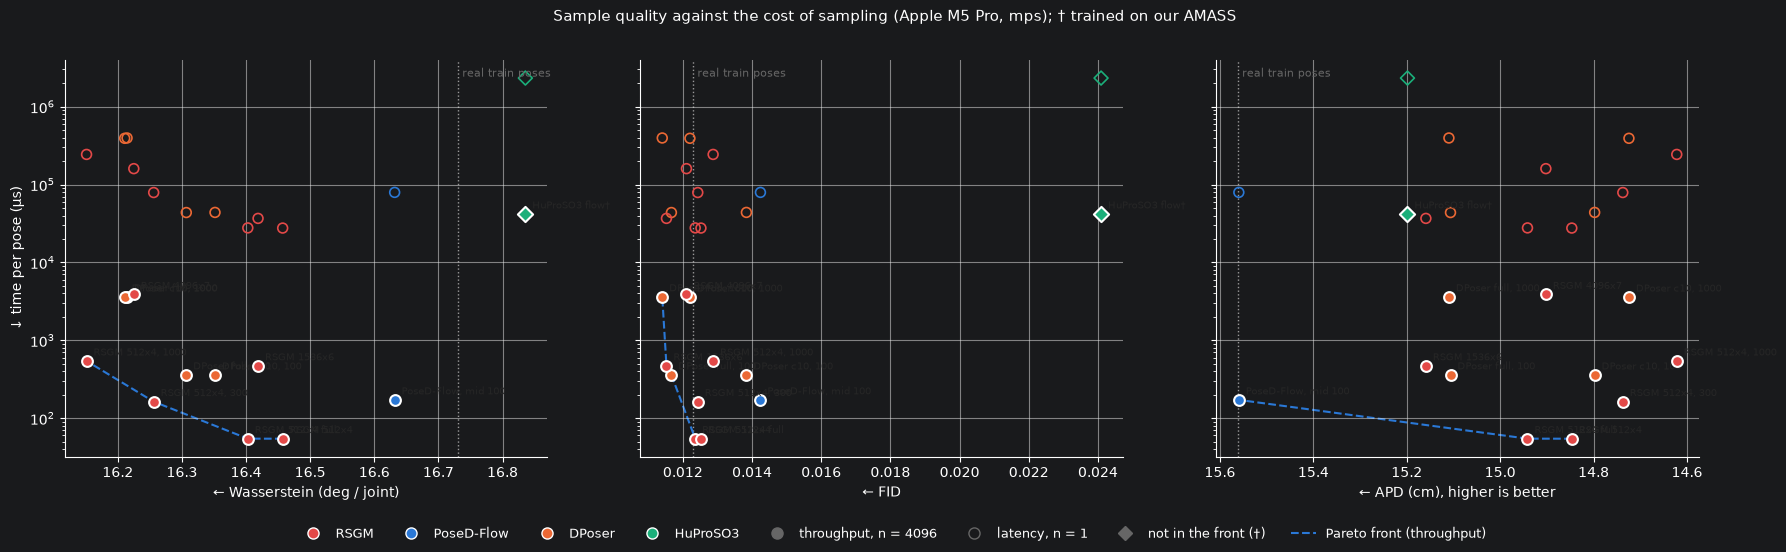

Wasserstein  front: RSGM 512x4 → RSGM 512x4 full → RSGM 512x4, 300 → RSGM 512x4, 1000
FID          front: RSGM 512x4 → RSGM 512x4 full → DPoser full, 100 → RSGM 1536x6 → DPoser full, 1000
APD          front: RSGM 512x4 → RSGM 512x4 full → PoseD-Flow, mid 100


In [6]:
def pareto(rows, metric, lower_better):
    """The rows on the front, from the fastest: each is better on `metric` than every faster one."""
    sign = 1 if lower_better else -1
    front, best = [], np.inf
    for r in sorted(rows, key=lambda r: (r["us_per_pose"], sign * r[metric])):
        if sign * r[metric] < best:
            front.append(r)
            best = sign * r[metric]
    return front


rows = table
front_rows = [r for r in rows if r["name"] not in FRONT_EXCLUDE]
fig, axes = plt.subplots(1, len(METRICS), figsize=(6 * len(METRICS), 5.5), sharey=True)
for ax, (metric, (_, unit, lower_better)) in zip(axes, METRICS.items()):
    ax.axvline(REAL[metric], color="0.6", lw=1, ls=":", zorder=0)
    ax.annotate("real train poses", (REAL[metric], 1), xycoords=("data", "axes fraction"), xytext=(3, -12),
                textcoords="offset points", fontsize=8, color="0.4")
    front = pareto(front_rows, metric, lower_better)
    ax.plot([r[metric] for r in front], [r["us_per_pose"] for r in front], ls="--", lw=1.5, color="#2a78d6", zorder=1)
    for r in rows:
        c, marker = FAMILIES[r["family"]], "D" if r["name"] in FRONT_EXCLUDE else "o"
        ax.scatter(r[metric], r["us_per_pose"], s=60, marker=marker, color=c, edgecolor="white", lw=1.5, zorder=3)
        ax.scatter(r[metric], r["latency_ms"] * 1e3, s=50, marker=marker, facecolor="none", edgecolor=c, lw=1.2, zorder=2)
        ax.annotate(r["short"], (r[metric], r["us_per_pose"]), xytext=(5, 4), textcoords="offset points",
                    fontsize=7.5, color="0.15")
    ax.set_yscale("log")
    if not lower_better:
        ax.invert_xaxis()  # the better side on the left, as GRACE
    ax.set_xlabel(f"← {metric}" + (f" ({unit})" if unit else "") + ("" if lower_better else ", higher is better"))
    ax.grid(True, which="major", color="0.92", lw=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("↓ time per pose (µs)")
handles = [plt.Line2D([], [], marker="o", ls="", color=c, markeredgecolor="white", markersize=8, label=f) for f, c in FAMILIES.items()]
handles += [plt.Line2D([], [], marker="o", ls="", color="0.4", markersize=8, label=f"throughput, n = {BATCH}"),
            plt.Line2D([], [], marker="o", ls="", markerfacecolor="none", markeredgecolor="0.4", markersize=8, label="latency, n = 1"),
            plt.Line2D([], [], marker="D", ls="", color="0.4", markersize=7, label="not in the front (†)"),
            plt.Line2D([], [], ls="--", color="#2a78d6", label="Pareto front (throughput)")]
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False, fontsize=9)
fig.suptitle(f"Sample quality against the cost of sampling ({CHIP}, {DEVICE}); † trained on our AMASS", fontsize=11)
fig.tight_layout(rect=(0, 0.06, 1, 0.97))
plt.show()

for metric, (_, _, lower_better) in METRICS.items():
    print(f"{metric:12s} front: " + " → ".join(r["short"] for r in pareto(front_rows, metric, lower_better)))

## 6. Reading (proof of concept)

- Every model is one point at its own sampler: the steps are not swept yet, except RSGM 512x4 (100 / 300 / 1000) and
  DPoser (100 / 1000). A sweep of the steps (5–200) for RSGM, PoseD-Flow and DPoser would turn each into a curve.
- The differences in quality are small against the noise: the ± of the metrics (in `posedflow_vs_rsgm.ipynb`) is of
  the order of the gaps between the points. The front on one metric is therefore not robust yet.
- † models are trained on other data than they are evaluated on; their quality is a lower bound.
- The times depend on this machine; on a GPU the ratio of the flow to the ODE/SDE models may differ.